# Declaración responsable sobre autoría y uso ético de inteligencia artificial, otros recursos o ayuda externa

Con la entrega de esta tarea, declaro de manera responsable que
es el resultado de mi trabajo intelectual personal y creativo, y que ha sido elaborado de acuerdo con los principios éticos y las normas de integridad vigentes en la comunidad académica y, más
específicamente, en la [Universidad Complutense de Madrid](https://www.ucm.es/file/declaracion-responsable-sobre-autoria-y-uso-%C3%89tico-de-herramientas-de-ia).

Soy, pues, autor del material aquí incluido y, cuando no ha sido así y he tomado el material de
otra fuente, lo he citado o bien he declarado su procedencia de forma clara -incluidas, en su
caso, herramientas de inteligencia artificial-. Las ideas y aportaciones principales incluidas en este trabajo, y que acreditan la adquisición de competencias, son mías y no proceden de otras fuentes o han sido reescritas usando material de otras fuentes.

Antes de entregar esta tarea, asegúrate de que todo funcione como se espera:

1. Reinicia el kernel  
   *(En la barra de menú, selecciona **Kernel → Restart**)*  

2. Ejecuta todas las celdas  
   *(En la barra de menú, selecciona **Cell → Run All**)*  

3. Asegúrate de completar todos los lugares donde aparezca:  
   - `YOUR CODE HERE`  
   - `"YOUR ANSWER HERE"`
     
4. Debes borrar las instrucciones que pone `raise NotImplementedError()`

5. Así como tu **nombre** a continuación:

In [1]:
NOMBRE = "JAIME RUIZ LÓPEZ-ALVARADO"

## Notas para la entrega

* Se deben rellenar todos los cuadernos sin cambiar el nombre.
* Es impor
* Se debe comprimir la carpeta `tarea_final` en un fichero `.zip`, llamado `tarea_final.zip`.
  
  **Importante**: por favor, no se entreguen ficheros `.rar`.

* Los ficheros CSV son bastante grandes y no son necesario incluirlos. Por eso es **importante** boorrarlos andes de generar el fichero comprimido.
* También es importante borrar los ficheros auxiliares como `*.ipynb_checkpoints`, `.mypy_cache`, `__pycache` y otros fiche.
* Subir el fichero comprimido al campus virtual.

# Ejercicio de Programación en Python: Web Scraping de Datos Abiertos de Madrid

Hasta ahora hemos trabajado siempre con un fichero CSV que ya teníamos descargado. En este cuaderno vamos a construir, paso a paso, el mecanismo para **descargar automáticamente** los ficheros de multas directamente del [Portal de Datos Abiertos del Ayuntamiento de Madrid](https://datos.madrid.es), usando `requests` y `bs4` (BeautifulSoup) — **no está permitido usar Selenium ni ningún otro navegador automatizado**, esto debe resolverse solo con peticiones HTTP y parseo de HTML.

El objetivo final es una función `get_data(year, month)` que, si el fichero `{year}_{month}.csv` ya existe en disco, lo use directamente, y si no, lo busque y descargue de la web. Con eso, montaremos un gráfico de multas mensuales entre dos fechas.

## Cómo encontrar los datos a mano (antes de programar nada)

Antes de escribir código conviene explorar la web con el navegador:

1. Abre <https://datos.madrid.es/dataset/210104-0-multas-circulacion-detalle/downloads> (la pestaña **"Descargas"** del dataset, no la de "Información").
2. Verás un listado organizado por año y, dentro de cada año, por mes.
3. Si inspeccionas el HTML (botón derecho → Inspeccionar), verás que los datos de cada mes están dentro de un `<div>` con `data-key="{año}-{Mes}"` (por ejemplo `data-key="2026-Enero"`, con el mes en español y con la primera letra en mayúscula). **Ojo:** ese mismo `data-key` aparece más de una vez en la página (hay un índice lateral que lo repite); el bloque que realmente contiene los enlaces de descarga es el que, además, contiene un enlace con un `title` que empieza por `"Detalle"`.
4. Dentro de ese bloque hay más de un recurso disponible para el mismo mes: el que queremos tiene un enlace `<a title="Detalle. Enero 2026">`; hay otro con `<a title="Agrupadas-excluidas. Enero 2026">` que **no** nos interesa (son datos agregados, no el detalle fila a fila).
5. A diferencia de la página de información que usábamos antes, aquí el propio bloque de descarga **ya incluye el enlace directo al CSV**: un botón "Descarga" (`<a class="... resource-type-data" href="...">`) cuyo `href` apunta directamente al fichero, sin necesidad de construir la URL a mano.
6. El contenido del fichero descargado debe decodificarse con el *encoding* `'iso-8859-15'`.

Vamos a programar cada uno de estos pasos como un ejercicio independiente, de forma que puedas comprobarlos uno a uno antes de combinarlos.

---

## Celda de Configuración: Importación de Módulos

Reutilizamos, como en `E2_numpy.ipynb`, la constante `MONTHS` de `E1_analisis_fichero.ipynb` mediante `ipynb.fs.defs`; y también la función `load_dataframe` de `E3_pandas.ipynb` (la usaremos en el Ejercicio 7 en lugar de escribir de nuevo una función de carga). Como ambos nombres de módulo empiezan por una letra, basta con `import ipynb` seguido de `from ipynb.fs.defs.E1_analisis_fichero import MONTHS` y `from ipynb.fs.defs.E3_pandas import load_dataframe`.

Importa en la siguiente celda `requests`, `BeautifulSoup` (de `bs4`), `pandas`, `os`, `doctest`, el módulo `testing`, y `MONTHS`/`load_dataframe` tal y como se explica arriba. En este ejercicio analizaremos el mismo fichero `2023_nov.csv` del que vemos las 10 primeras líneas.


In [2]:
with open('2023_nov.csv') as f:
    for _ in range(10):
        line = next(f).strip()
        print(line)

CALIFICACION;LUGAR;MES;ANIO;HORA;IMP_BOL;DESCUENTO; PUNTOS;DENUNCIANTE;HECHO-BOL;VEL_LIMITE;VEL_CIRCULA ;COORDENADA-X;COORDENADA-Y
LEVE      ;BRAVO MURILLO, 261                      ;11;2023;09.50;  60.00;SI;0;AGENTES DE MOVILIDAD          ;NO ADVERTIR LA MANIOBRAAL RESTO DE USUARIOS DE LA VÍA.                                                                       ;   ;   ;    4400.56;   44787.09
GRAVE     ;PEDRO RICO, 1                           ;11;2023;08.38; 200.00;SI;0;AGENTES DE MOVILIDAD          ;ESTACIONAR EN ZONA SEÑALIZADA PARA USO EXCLUSIVO DE PERSONAS CON MOVILIDAD REDUCIDA.                                         ;   ;   ;    4416.15;   44816.22
GRAVE     ;VELAZQUEZ, 80                           ;11;2023;11.33; 200.00;SI;3;AGENTES DE MOVILIDAD          ;CONDUCIR UTILIZANDO AURICULAR O DISPOSITIVO QUE DISMINUYA LA ATENCIÓN PERMANENTE A LA CONDUCCIÓN.                            ;   ;   ;    4419.77;   44753.77
LEVE      ;GERARDO CORDON, 53                      ;11;2023;11.27

Los tests de este cuaderno también están en el fichero `testing.py`, junto a los de los cuadernos anteriores.

In [3]:
import subprocess
import sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'requests', 'beautifulsoup4', 'ipynb', 'pytest'])

Defaulting to user installation because normal site-packages is not writeable


0

In [4]:
# Imports
import pytest
import doctest
import os
import testing_04 as testing
import requests
from bs4 import BeautifulSoup, Tag
import pandas as pd
import matplotlib.pyplot as plt
import ipynb
from ipynb.fs.defs.E1_analisis_fichero import MONTHS
from ipynb.fs.defs.E3_pandas import load_dataframe


# Constants
SITE = "https://datos.madrid.es"
DOWNLOADS_PATH = "/dataset/210104-0-multas-circulacion-detalle/downloads"

MONTHS_ES = dict(zip(MONTHS, ['enero', 'febrero', 'marzo', 'abril', 'mayo', 'junio',
                              'julio', 'agosto', 'septiembre', 'octubre',
                              'noviembre', 'diciembre']))

MONTHS_INT = {month: index for index, month in enumerate(MONTHS)}

PIE_MIN_PCT = 2.0  


## Ejercicio 1: Descargar y Parsear una Página Web

Escribe una función con la cabecera `def fetch_dataset_page(url: str) -> BeautifulSoup:` que reciba una URL genérica, haga una petición HTTP con `requests` a esa URL, compruebe que la respuesta ha sido correcta, y devuelva un objeto `BeautifulSoup` construido a partir del HTML de la página (usa el parser `'html.parser'`). La función no debe asumir ninguna URL concreta; se usará después pasándole `SITE + DOWNLOADS_PATH`, pero podría usarse con cualquier otra página.

**Nota:** este ejercicio necesita conexión a Internet real a `datos.madrid.es`; no se puede resolver con datos simulados.

In [5]:
def fetch_dataset_page(url: str) -> BeautifulSoup:
    """Descarga una página y la devuelve parseada con BeautifulSoup.

    Lanza requests.HTTPError si la respuesta tiene un código de error.

    Args:
        url: Dirección completa de la página.

    Returns:
        BeautifulSoup: HTML parseado con 'html.parser'.

    Examples:
        >>> isinstance(fetch_dataset_page(SITE + DOWNLOADS_PATH), BeautifulSoup)
        True
    """
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    return BeautifulSoup(response.text, 'html.parser')

### Auto comprobación

La salida de la siguiente casilla debe confirmar que se ha encontrado algún bloque de noviembre de 2023 dentro de la página.

In [6]:
def check_fetch_dataset_page_result():
    soup = fetch_dataset_page(SITE + DOWNLOADS_PATH)
    print(type(soup))
    print('¿Existen bloques de 2023-Noviembre?', len(soup.find_all(attrs={'data-key': '2023-Noviembre'})))
check_fetch_dataset_page_result()

<class 'bs4.BeautifulSoup'>
¿Existen bloques de 2023-Noviembre? 8


Comprueba tus doctests

In [7]:
doctest.run_docstring_examples(fetch_dataset_page, globals(), verbose=True)

Finding tests in NoName
Trying:
    isinstance(fetch_dataset_page(SITE + DOWNLOADS_PATH), BeautifulSoup)
Expecting:
    True


ok


Comprueba la calidad del docstring

In [8]:
help(fetch_dataset_page)

Help on function fetch_dataset_page in module __main__:

fetch_dataset_page(url: str) -> bs4.BeautifulSoup
    Descarga una página y la devuelve parseada con BeautifulSoup.
    
    Lanza requests.HTTPError si la respuesta tiene un código de error.
    
    Args:
        url: Dirección completa de la página.
    
    Returns:
        BeautifulSoup: HTML parseado con 'html.parser'.
    
    Examples:
        >>> isinstance(fetch_dataset_page(SITE + DOWNLOADS_PATH), BeautifulSoup)
        True



### Comprobación automática del código

In [9]:
testing.test_fetch_dataset_page(fetch_dataset_page)

test_fetch_dataset_page OK


In [10]:
testing.test_fetch_dataset_page_typehints(fetch_dataset_page)

check type hints OK


In [11]:
testing.test_docstring(fetch_dataset_page)

docstring OK


In [12]:
testing.test_doctests(fetch_dataset_page, globals())

doctests OK


A partir de aquí reutilizamos `SOUP`, calculado con la función que acabas de implementar, en el Ejercicio 2.

In [13]:
SOUP = fetch_dataset_page(SITE + DOWNLOADS_PATH)
type(SOUP)

bs4.BeautifulSoup

## Ejercicio 2: Encontrar el Bloque de Recurso "Detalle" de un Mes

Escribe una función con la cabecera `def find_resource_block(soup: BeautifulSoup, year: int, month: str) -> Tag:` que reciba la página ya parseada (como la de `fetch_dataset_page`), un año y un mes (cadena de 3 letras en inglés, como en `E1_analisis_fichero.ipynb`), y devuelva el `Tag` de BeautifulSoup correspondiente al bloque de recurso `"Detalle"` de ese mes (el elemento con clase `"tracked-resource-item"` que contiene el enlace de descarga).

Pasos:
1. Convierte `month` a su nombre en español, con la primera letra en mayúscula (usa `MONTHS_ES[month].capitalize()`), y construye la clave `f'{year}-{mes}'` (por ejemplo `'2026-Enero'`).
2. Busca **todos** los elementos con ese `data-key` (`soup.find_all(attrs={'data-key': clave})`); recuerda que esa clave aparece repetida en la página (hay un índice lateral que no contiene enlaces), así que debes quedarte con el bloque que sí contiene un enlace `<a>` cuyo `title` empiece por `"Detalle"`. Si no encuentras ninguno, lanza un `ValueError`.
3. Dentro de ese bloque, busca el enlace `<a title=f'Detalle. {mes} {year}'>` exacto (no el de `"Agrupadas-excluidas"`). Si no lo encuentras, lanza un `ValueError`.
4. Devuelve el contenedor `<div class="tracked-resource-item">` al que pertenece ese enlace (usa `.find_parent('div', class_='tracked-resource-item')`).

**Nota:** este ejercicio necesita conexión a Internet real (usa una `soup` obtenida con `fetch_dataset_page`).

In [14]:
def find_resource_block(soup: BeautifulSoup, year: int, month: str) -> Tag:
    """Devuelve el bloque <div class="tracked-resource-item"> del recurso
    "Detalle" de un mes en la página de descargas.

    Args:
        soup: Página de descargas parseada (ver fetch_dataset_page).
        year: Año de los datos.
        month: Mes en inglés abreviado a 3 letras ('jan', ..., 'dec').

    Returns:
        Tag: El bloque del recurso "Detalle".

    Raises:
        ValueError: Si no hay bloque o enlace "Detalle" para ese mes.

    Examples:
        >>> soup = fetch_dataset_page(SITE + DOWNLOADS_PATH)
        >>> find_resource_block(soup, 2023, 'nov')['class']
        ['tracked-resource-item']
    """
    mes = MONTHS_ES[month.lower()].capitalize()
    key = f'{year}-{mes}'

    candidates = soup.find_all(attrs={'data-key': key})
    blocks = [block for block in candidates
              if block.find('a', title=lambda t: t and t.startswith('Detalle'))]
    if not blocks:
        raise ValueError(f'No hay ningún bloque "Detalle" para {key}')

    link = blocks[0].find('a', title=f'Detalle. {mes} {year}')
    if link is None:
        raise ValueError(f'No se encuentra el enlace "Detalle. {mes} {year}"')

    return link.find_parent('div', class_='tracked-resource-item')

### Auto comprobación

La salida de la siguiente casilla debe mostrar el identificador del recurso de noviembre de 2023.

In [15]:
def check_find_resource_block_result():
    block = find_resource_block(SOUP, 2023, 'nov')
    print(block.get('data-resourceid'))
check_find_resource_block_result()

210104-335-multas-circulacion-detalle-csv


Comprueba tus doctests

In [16]:
doctest.run_docstring_examples(find_resource_block, globals(), verbose=True)

Finding tests in NoName
Trying:
    soup = fetch_dataset_page(SITE + DOWNLOADS_PATH)
Expecting nothing
ok
Trying:
    find_resource_block(soup, 2023, 'nov')['class']
Expecting:
    ['tracked-resource-item']
ok


Comprueba la calidad del docstring

In [17]:
help(find_resource_block)

Help on function find_resource_block in module __main__:

find_resource_block(soup: bs4.BeautifulSoup, year: int, month: str) -> bs4.element.Tag
    Devuelve el bloque <div class="tracked-resource-item"> del recurso
    "Detalle" de un mes en la página de descargas.
    
    Args:
        soup: Página de descargas parseada (ver fetch_dataset_page).
        year: Año de los datos.
        month: Mes en inglés abreviado a 3 letras ('jan', ..., 'dec').
    
    Returns:
        Tag: El bloque del recurso "Detalle".
    
    Raises:
        ValueError: Si no hay bloque o enlace "Detalle" para ese mes.
    
    Examples:
        >>> soup = fetch_dataset_page(SITE + DOWNLOADS_PATH)
        >>> find_resource_block(soup, 2023, 'nov')['class']
        ['tracked-resource-item']



### Comprobación automática del código

In [18]:
testing.test_find_resource_block(find_resource_block, SOUP)

test_find_resource_block OK


In [19]:
testing.test_find_resource_block_typehints(find_resource_block)

check type hints OK


In [20]:
testing.test_docstring(find_resource_block)

docstring OK


In [21]:
testing.test_doctests(find_resource_block, globals())

doctests OK


## Ejercicio 3: Extraer la URL de Descarga Directa

A diferencia del planteamiento anterior, aquí el bloque de recurso (el que devuelve `find_resource_block`) **ya contiene** el enlace de descarga directa: un botón "Descarga" (`<a class="... resource-type-data" href="...">`). Escribe una función con la cabecera `def extract_download_url(resource_block: Tag) -> str:` que reciba ese bloque y devuelva la URL absoluta de descarga.

Pasos:
1. Busca dentro del bloque el enlace con clase `'resource-type-data'` (`resource_block.find('a', class_='resource-type-data')`). Si no lo encuentras, lanza un `ValueError`.
2. Si su `href` empieza por `/` (es una URL relativa), añádele `SITE` delante para obtener la URL absoluta.

Este ejercicio **no necesita conexión a Internet**: se puede probar con un trozo de HTML de ejemplo.

In [22]:
def extract_download_url(resource_block: Tag) -> str:
    """Devuelve la URL absoluta del enlace de descarga de un bloque.

    Args:
        resource_block: Bloque devuelto por find_resource_block.

    Returns:
        str: URL completa del fichero.

    Raises:
        ValueError: Si el bloque no tiene enlace de descarga.

    Examples:
        >>> html = '<div><a class="resource-type-data" href="/multas.csv">Descarga</a></div>'
        >>> extract_download_url(BeautifulSoup(html, 'html.parser').div)
        'https://datos.madrid.es/multas.csv'
    """
    link = resource_block.find('a', class_='resource-type-data')
    if link is None or not link.get('href'):
        raise ValueError("El bloque no tiene enlace de descarga")

    href = link['href']
    return SITE + href if href.startswith('/') else href

### Auto comprobación

La salida de la siguiente casilla debe mostrar la URL de descarga directa a partir del bloque de noviembre de 2023.

In [23]:
def check_extract_download_url_result():
    block = find_resource_block(SOUP, 2023, 'nov')
    print(extract_download_url(block))
check_extract_download_url_result()

https://datos.madrid.es/dataset/210104-0-multas-circulacion-detalle/resource/210104-335-multas-circulacion-detalle-csv/download/210104-335-multas-circulacion-detalle-csv.csv


Comprueba tus doctests

In [24]:
doctest.run_docstring_examples(extract_download_url, globals(), verbose=True)

Finding tests in NoName
Trying:
    html = '<div><a class="resource-type-data" href="/multas.csv">Descarga</a></div>'
Expecting nothing
ok
Trying:
    extract_download_url(BeautifulSoup(html, 'html.parser').div)
Expecting:
    'https://datos.madrid.es/multas.csv'
ok


Comprueba la calidad del docstring

In [25]:
help(extract_download_url)

Help on function extract_download_url in module __main__:

extract_download_url(resource_block: bs4.element.Tag) -> str
    Devuelve la URL absoluta del enlace de descarga de un bloque.
    
    Args:
        resource_block: Bloque devuelto por find_resource_block.
    
    Returns:
        str: URL completa del fichero.
    
    Raises:
        ValueError: Si el bloque no tiene enlace de descarga.
    
    Examples:
        >>> html = '<div><a class="resource-type-data" href="/multas.csv">Descarga</a></div>'
        >>> extract_download_url(BeautifulSoup(html, 'html.parser').div)
        'https://datos.madrid.es/multas.csv'



### Comprobación automática del código

In [26]:
testing.test_extract_download_url(extract_download_url)

test_extract_download_url OK


In [27]:
testing.test_extract_download_url_typehints(extract_download_url)

check type hints OK


In [28]:
testing.test_docstring(extract_download_url)

docstring OK


In [29]:
testing.test_doctests(extract_download_url, globals())

doctests OK


## Ejercicio 4: Descargar y Guardar el CSV de un Mes

Escribe una función con la cabecera `def download_month_csv(year: int, month: str) -> str:` que combine los tres ejercicios anteriores para descargar el fichero CSV de un mes y guardarlo en disco:

1. Consigue la página con `fetch_dataset_page(SITE + DOWNLOADS_PATH)`.
2. Encuentra el bloque del recurso con `find_resource_block`.
3. Extrae la URL de descarga con `extract_download_url`.
4. Descarga el contenido con `requests`. El fichero que sirve `datos.madrid.es` está codificado en `'iso-8859-15'`, así que **no uses `resp.text`** (que dejaría que `requests` adivinase mal la codificación): usa `resp.content` (los bytes en crudo) y decodifícalos tú mismo con `.decode('iso-8859-15')`. Esto te da un `str` de Python con las tildes de `LUGAR` o `HECHO-BOL` ya correctas.
5. Guarda ese `str` en un fichero llamado `{year}_{month}.csv` (por ejemplo, `2023_nov.csv`), pero esta vez escribiéndolo con codificación `'utf-8'` (no la codificación original del fichero descargado).
6. Devuelve la ruta del fichero guardado.

**Nota:** este ejercicio necesita conexión a Internet real.

In [30]:
def download_month_csv(year: int, month: str) -> str:
    """Descarga el CSV de un mes y lo guarda como '{year}_{month}.csv' en UTF-8.

    El fichero de la web viene en 'iso-8859-15', así que se decodifica
    con esa codificación antes de guardarlo.

    Args:
        year: Año de los datos.
        month: Mes en inglés abreviado a 3 letras ('jan', ..., 'dec').

    Returns:
        str: Ruta del fichero guardado.

    Examples:
        >>> download_month_csv(2023, 'oct')
        '2023_oct.csv'
    """
    soup = fetch_dataset_page(SITE + DOWNLOADS_PATH)
    block = find_resource_block(soup, year, month)
    url = extract_download_url(block)

    resp = requests.get(url, timeout=120)
    resp.raise_for_status()
    text = resp.content.decode('iso-8859-15')

    filepath = f'{year}_{month.lower()}.csv'
    with open(filepath, 'w', encoding='utf-8', newline='') as f:
        f.write(text)
    return filepath

### Auto comprobación

La salida de la siguiente casilla debe mostrar la ruta del fichero descargado y su primera línea (la cabecera).

In [31]:
def check_download_month_csv_result():
    filepath = download_month_csv(2023, 'dec')
    print(filepath)
    with open(filepath, encoding='utf-8') as f:
        print(f.readline().strip())
check_download_month_csv_result()

2023_dec.csv
CALIFICACION;LUGAR;MES;ANIO;HORA;IMP_BOL;DESCUENTO; PUNTOS;DENUNCIANTE;HECHO-BOL;VEL_LIMITE;VEL_CIRCULA ;COORDENADA-X;COORDENADA-Y


Comprueba tus doctests

In [32]:
doctest.run_docstring_examples(download_month_csv, globals(), verbose=True)

Finding tests in NoName
Trying:
    download_month_csv(2023, 'oct')
Expecting:
    '2023_oct.csv'
ok


Comprueba la calidad del docstring

In [33]:
help(download_month_csv)

Help on function download_month_csv in module __main__:

download_month_csv(year: int, month: str) -> str
    Descarga el CSV de un mes y lo guarda como '{year}_{month}.csv' en UTF-8.
    
    El fichero de la web viene en 'iso-8859-15', así que se decodifica
    con esa codificación antes de guardarlo.
    
    Args:
        year: Año de los datos.
        month: Mes en inglés abreviado a 3 letras ('jan', ..., 'dec').
    
    Returns:
        str: Ruta del fichero guardado.
    
    Examples:
        >>> download_month_csv(2023, 'oct')
        '2023_oct.csv'



### Comprobación automática del código

In [34]:
testing.test_download_month_csv(download_month_csv)

test_download_month_csv OK


In [35]:
testing.test_download_month_csv_typehints(download_month_csv)

check type hints OK


In [36]:
testing.test_docstring(download_month_csv)

docstring OK


In [37]:
testing.test_doctests(download_month_csv, globals())

doctests OK


## Ejercicio 5: `get_data`, con Caché en Disco

Escribe la función principal de este cuaderno, con la cabecera `def get_data(year: int, month: str) -> str:`: si el fichero `{year}_{month}.csv` ya existe en el directorio actual, devuelve directamente su ruta (sin descargar nada); si no existe, lo descarga con `download_month_csv` y devuelve la ruta resultante.

De esta forma, cada mes solo se descarga una vez, y las siguientes veces que se pida se reutiliza el fichero local — igual que ya veníamos haciendo con `2023_nov.csv` en los cuadernos anteriores.

In [38]:
def get_data(year: int, month: str) -> str:
    """Devuelve la ruta del CSV de un mes, descargándolo solo si hace falta.

    Si el fichero '{year}_{month}.csv' ya existe en el directorio actual,
    se devuelve su ruta sin descargar nada (caché en disco). Si no existe,
    se descarga con download_month_csv.

    Args:
        year: Año de los datos.
        month: Mes en inglés abreviado a 3 letras ('jan', ..., 'dec').

    Returns:
        str: Ruta del fichero CSV del mes (p. ej. '2023_nov.csv').

    Examples:
        2023_nov.csv ya existe, así que no se descarga nada:

        >>> get_data(2023, 'nov')
        '2023_nov.csv'
    """
    filepath = f'{year}_{month.lower()}.csv'
    if os.path.exists(filepath):
        return filepath
    return download_month_csv(year, month)


### Auto comprobación

La salida de la siguiente casilla debe mostrar la ruta de `2023_nov.csv` (ya lo tenemos en disco, así que no debería descargar nada) y la de un mes que aún no tengamos.

In [39]:
def check_get_data_result():
    print(get_data(2023, 'nov'))
    print(get_data(2024, 'jan'))
check_get_data_result()

2023_nov.csv
2024_jan.csv


Comprueba tus doctests

In [40]:
doctest.run_docstring_examples(get_data, globals(), verbose=True)

Finding tests in NoName
Trying:
    get_data(2023, 'nov')
Expecting:
    '2023_nov.csv'
ok


Comprueba la calidad del docstring

In [41]:
help(get_data)

Help on function get_data in module __main__:

get_data(year: int, month: str) -> str
    Devuelve la ruta del CSV de un mes, descargándolo solo si hace falta.
    
    Si el fichero '{year}_{month}.csv' ya existe en el directorio actual,
    se devuelve su ruta sin descargar nada (caché en disco). Si no existe,
    se descarga con download_month_csv.
    
    Args:
        year: Año de los datos.
        month: Mes en inglés abreviado a 3 letras ('jan', ..., 'dec').
    
    Returns:
        str: Ruta del fichero CSV del mes (p. ej. '2023_nov.csv').
    
    Examples:
        2023_nov.csv ya existe, así que no se descarga nada:
    
        >>> get_data(2023, 'nov')
        '2023_nov.csv'



### Comprobación automática del código

In [42]:
testing.test_get_data(get_data)

test_get_data OK


In [43]:
testing.test_get_data_typehints(get_data)

check type hints OK


In [44]:
testing.test_docstring(get_data)

docstring OK


In [45]:
testing.test_doctests(get_data, globals())

doctests OK


## Ejercicio 6: Rango de Meses entre Dos Fechas

Antes de poder pedir varios meses seguidos, necesitamos poder enumerarlos. Escribe una función con la cabecera `def month_range(start_year: int, start_month: str, end_year: int, end_month: str) -> list[tuple[int, str]]:` que devuelva la lista de pares `(año, mes)` desde la fecha de inicio hasta la de fin, ambas incluidas, en orden cronológico.

Usa la constante `MONTHS_INT` (definida en la celda de constantes a partir de `MONTHS`, importada de `E1_analisis_fichero.ipynb`) para convertir cada mes en un índice absoluto: `año * 12 + MONTHS_INT[mes]`. Con dos índices así puedes recorrer el rango con un `range` y reconstruir cada `(año, mes)` con `divmod` (o `//` y `%`) entre 12.

Si la fecha de fin es anterior a la de inicio, la función debe lanzar un `ValueError`.

Este ejercicio **no necesita conexión a Internet**.


In [46]:
def month_range(start_year: int, start_month: str,
                end_year: int, end_month: str) -> list[tuple[int, str]]:
    """Devuelve los pares (año, mes) entre dos fechas, ambas incluidas.

    Args:
        start_year: Año de inicio.
        start_month: Mes de inicio ('jan', ..., 'dec').
        end_year: Año de fin.
        end_month: Mes de fin ('jan', ..., 'dec').

    Returns:
        list[tuple[int, str]]: Pares (año, mes) en orden cronológico.

    Raises:
        ValueError: Si la fecha de fin es anterior a la de inicio.

    Examples:
        >>> month_range(2023, 'dec', 2024, 'jan')
        [(2023, 'dec'), (2024, 'jan')]
    """
    start = start_year * 12 + MONTHS_INT[start_month.lower()]
    end = end_year * 12 + MONTHS_INT[end_month.lower()]
    if end < start:
        raise ValueError('La fecha de fin es anterior a la de inicio')

    return [(index // 12, MONTHS[index % 12]) for index in range(start, end + 1)]

### Auto comprobación

La salida de la siguiente casilla debe mostrar los meses entre noviembre de 2023 y febrero de 2024.

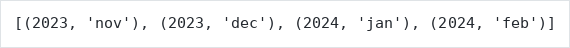

In [47]:
def check_month_range_result():
    print(month_range(2023, 'nov', 2024, 'feb'))
check_month_range_result()

[(2023, 'nov'), (2023, 'dec'), (2024, 'jan'), (2024, 'feb')]


Comprueba tus doctests

In [48]:
doctest.run_docstring_examples(month_range, globals(), verbose=True)

Finding tests in NoName
Trying:
    month_range(2023, 'dec', 2024, 'jan')
Expecting:
    [(2023, 'dec'), (2024, 'jan')]
ok


Comprueba la calidad del docstring

In [49]:
help(month_range)

Help on function month_range in module __main__:

month_range(start_year: int, start_month: str, end_year: int, end_month: str) -> list[tuple[int, str]]
    Devuelve los pares (año, mes) entre dos fechas, ambas incluidas.
    
    Args:
        start_year: Año de inicio.
        start_month: Mes de inicio ('jan', ..., 'dec').
        end_year: Año de fin.
        end_month: Mes de fin ('jan', ..., 'dec').
    
    Returns:
        list[tuple[int, str]]: Pares (año, mes) en orden cronológico.
    
    Raises:
        ValueError: Si la fecha de fin es anterior a la de inicio.
    
    Examples:
        >>> month_range(2023, 'dec', 2024, 'jan')
        [(2023, 'dec'), (2024, 'jan')]



### Comprobación automática del código

In [50]:
testing.test_month_range(month_range)

test_month_range OK


In [51]:
testing.test_month_range_typehints(month_range)

check type hints OK


In [52]:
testing.test_docstring(month_range)

docstring OK


In [53]:
testing.test_doctests(month_range, globals())

doctests OK


## Ejercicio 7: Todos los Datos en un DataFrame de Pandas

Escribe una función con la cabecera `def download_all_data(start_year: int, start_month: str, end_year: int, end_month: str) -> pd.DataFrame:` que, para cada mes entre las dos fechas (ambas incluidas), obtenga el fichero con `get_data` y lo cargue con `load_dataframe` (la función del Ejercicio 1 de `E3_pandas.ipynb`, no `load_fines_data` de `E1`), y devuelva **un único** `DataFrame` con todas las multas de todos esos meses juntas (usa `pd.concat`, reiniciando el índice).

**Nota:** si alguno de los meses no está ya descargado, este ejercicio necesitará conexión a Internet.

In [54]:
def download_all_data(start_year: int, start_month: str,
                      end_year: int, end_month: str) -> pd.DataFrame:
    """Carga en un único DataFrame las multas de todos los meses de un rango.

    Para cada mes entre las dos fechas (ambas incluidas) obtiene el fichero
    con get_data (que solo descarga si no está ya en disco), lo carga con
    load_dataframe y une todos los DataFrames con pd.concat, reiniciando
    el índice.

    Args:
        start_year: Año de inicio.
        start_month: Mes de inicio ('jan', ..., 'dec').
        end_year: Año de fin.
        end_month: Mes de fin ('jan', ..., 'dec').

    Returns:
        pd.DataFrame: Todas las multas de esos meses, con índice 0..n-1.

    Raises:
        ValueError: Si la fecha de fin es anterior a la de inicio.

    Examples:
        2023_nov.csv ya está en disco, así que no se descarga nada:

        >>> df = download_all_data(2023, 'nov', 2023, 'nov')
        >>> len(df)
        209657
        >>> df.index.equals(pd.RangeIndex(len(df)))
        True
    """
    frames = [load_dataframe(get_data(year, month))
              for year, month in month_range(start_year, start_month, end_year, end_month)]
    return pd.concat(frames, ignore_index=True)


### Auto comprobación

La salida de la siguiente casilla debe mostrar la forma del `DataFrame` combinado de noviembre y diciembre de 2023.

In [55]:
def check_download_all_data_result():
    df = download_all_data(2023, 'nov', 2023, 'dec')
    print(df.shape)
    print(df['DENUNCIANTE'].value_counts())
check_download_all_data_result()

(428364, 14)
DENUNCIANTE
SER                              168314
MEDIOS DE CAPTACION DE IMAGEN    134277
POLICIA MUNICIPAL                115732
AGENTES DE MOVILIDAD               6861
SACE                               3070
MOVILIDAD RADAR                     110
Name: count, dtype: int64


Comprueba tus doctests

In [65]:
doctest.run_docstring_examples(download_all_data, globals(), verbose=True)

Finding tests in NoName
Trying:
    df = download_all_data(2023, 'nov', 2023, 'nov')
Expecting nothing
ok
Trying:
    len(df)
Expecting:
    209657
ok
Trying:
    df.index.equals(pd.RangeIndex(len(df)))
Expecting:
    True
ok


Comprueba la calidad del docstring

In [57]:
help(download_all_data)

Help on function download_all_data in module __main__:

download_all_data(start_year: int, start_month: str, end_year: int, end_month: str) -> pandas.DataFrame
    Carga en un único DataFrame las multas de todos los meses de un rango.
    
    Para cada mes entre las dos fechas (ambas incluidas) obtiene el fichero
    con get_data (que solo descarga si no está ya en disco), lo carga con
    load_dataframe y une todos los DataFrames con pd.concat, reiniciando
    el índice.
    
    Args:
        start_year: Año de inicio.
        start_month: Mes de inicio ('jan', ..., 'dec').
        end_year: Año de fin.
        end_month: Mes de fin ('jan', ..., 'dec').
    
    Returns:
        pd.DataFrame: Todas las multas de esos meses, con índice 0..n-1.
    
    Raises:
        ValueError: Si la fecha de fin es anterior a la de inicio.
    
    Examples:
        2023_nov.csv ya está en disco, así que no se descarga nada:
    
        >>> df = download_all_data(2023, 'nov', 2023, 'nov')
       

### Comprobación automática del código

In [58]:
testing.test_download_all_data(download_all_data)

test_download_all_data OK


In [59]:
testing.test_download_all_data_typehints(download_all_data)

check type hints OK


In [60]:
testing.test_docstring(download_all_data)

docstring OK


In [61]:
testing.test_doctests(download_all_data, globals())

doctests OK


A partir de aquí reutilizamos `ALL_DATA`, calculado con la función que acabas de implementar, en el Ejercicio 8.

In [62]:
ALL_DATA = download_all_data(2023, 'nov', 2023, 'dec')
ALL_DATA.shape

(428364, 14)

## Ejercicio 8: Gráfico de Tarta por Denunciante

Escribe una función con la cabecera `def plot_complainant_pie(df: pd.DataFrame) -> None:` que reciba un `DataFrame` como el de `download_all_data` y muestre un **gráfico de tarta** con el porcentaje de multas de cada tipo de denunciante (`DENUNCIANTE`). El gráfico debe tener título y mostrar el porcentaje de cada porción. Las porciones deben estar ordenadas en sentido anti-horario.

Como hay denunciantes con porcentajes muy pequeños, **no pongas los nombres directamente sobre las porciones** (se pegan unos a otros); usa una leyenda aparte (`plt.legend`) para los nombres, y evita mostrar el porcentaje de las porciones casi nulas para que no se solape (por ejemplo, con una función para `autopct` que devuelva `''` por debajo de un umbral). La salida debe ser similar a la siguiente:

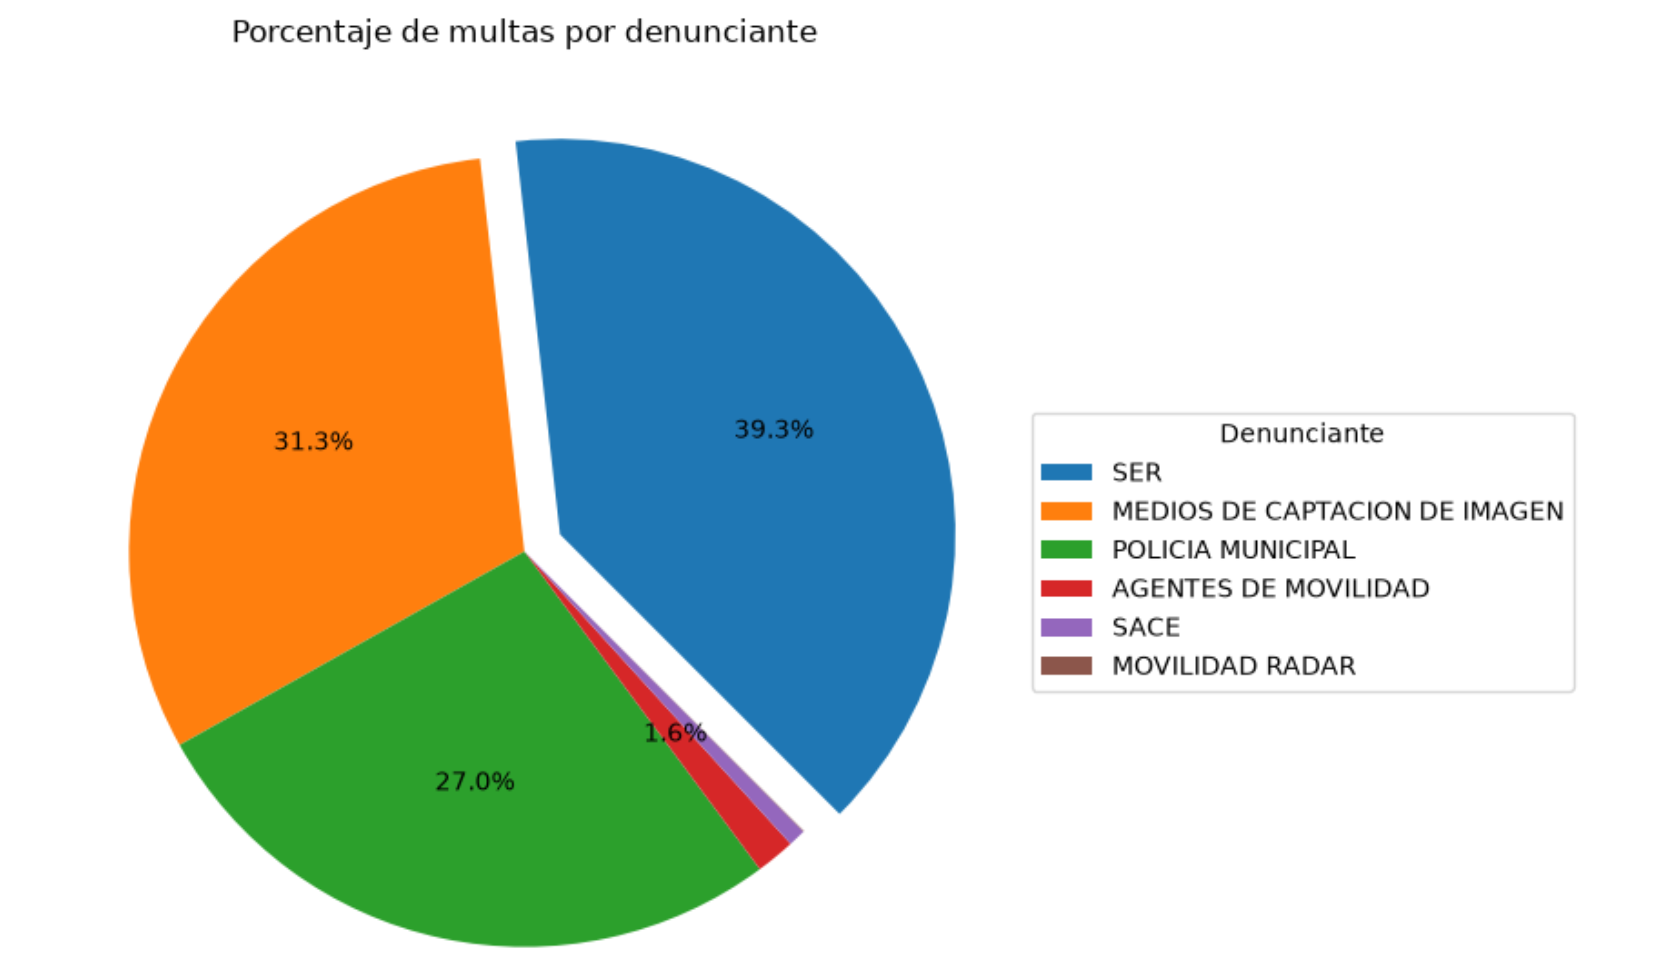

**Este ejercicio se corrige de forma manual** (4 puntos). Asegúrate de que la celda de la solución, al ejecutarla, muestra el gráfico terminado (llama a tu función al final de la misma celda, usando `ALL_DATA`).

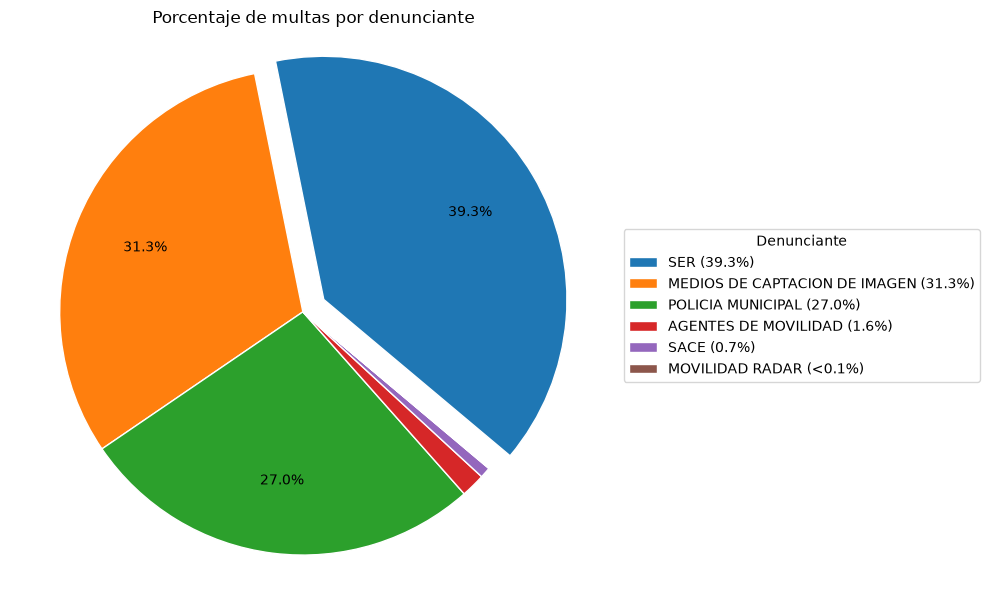

In [63]:
def plot_complainant_pie(df: pd.DataFrame) -> None:
    """Muestra un gráfico de tarta con el porcentaje de multas por denunciante.

    Cuenta las multas de cada DENUNCIANTE (de mayor a menor) y las dibuja en
    sentido antihorario empezando arriba. La porción mayor se separa un poco.
    Los nombres van en una leyenda aparte y los porcentajes menores que
    PIE_MIN_PCT no se escriben, para que no se solapen.

    Args:
        df: DataFrame de multas con la columna DENUNCIANTE
            (ver download_all_data).

    Returns:
        None. Muestra el gráfico.
    """
    counts = df['DENUNCIANTE'].value_counts()
    explode = [0.1] + [0] * (len(counts) - 1)

    fig, ax = plt.subplots(figsize=(10, 6))
    wedges, _, _ = ax.pie(
        counts.values,
        explode=explode,
        startangle=320,
        counterclock=True,
        autopct=lambda pct: f'{pct:.1f}%' if pct >= PIE_MIN_PCT else '',
        pctdistance=0.7,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1},
    )

    ax.set_title('Porcentaje de multas por denunciante')
    ax.legend(
        wedges,
        [f'{name} ({pct:.1f}%)' if pct >= 0.1 else f'{name} (<0.1%)'
         for name, pct in zip(counts.index, counts / counts.sum() * 100)],
        title='Denunciante',
        loc='center left',
        bbox_to_anchor=(1, 0.5),
    )
    ax.axis('equal')

    fig.tight_layout()
    plt.show()


plot_complainant_pie(ALL_DATA)


**Criterios de corrección manual:**
- Usa la columna `DENUNCIANTE` de `ALL_DATA` (o un cálculo equivalente) para contar las multas por denunciante.
- El gráfico es un gráfico de tarta (`plt.pie` u otro equivalente).
- Tiene título; los nombres de los denunciantes están en una leyenda aparte (no pegados a las porciones).
- Muestra el porcentaje de cada porción, sin que los textos se solapen entre sí.
- Los datos representados son correctos (coinciden con los recuentos de `ALL_DATA`).
- Las porciones están ordenadas en sentido antihorario.


## Comprobación final antes de entregar

**Guarda el cuaderno ahora (Ctrl+S / Cmd+S)** y, después, ejecuta la siguiente casilla. Comprueba que no haya identificadores de celda duplicados (algo que suele pasar al copiar una celda de solución o de test en vez de escribir en la tuya propia).

In [64]:
testing.check_duplicated_ids('E4_webscrapping.ipynb')

OK. No se han encontrado grade_id duplicados.
